# Customer Cohort & Churn Analytics (IBM Telco Churn)
**Datheon Data Analytics & Power BI Internship, Task 3**

**Author:** Promise Jeneka Taiwo

**Goal:** Group customers into cohorts by how long they have been subscribed (tenure) and contract type, measure how many leave (churn), and find out what drives churn so the company can keep more customers.

**Tools:** Python (Pandas, Matplotlib, Seaborn) in Jupyter Notebook

## 1. Loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("telco_customer_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data cleaning

Each row is one customer. First I checked the data types and missing values.

In [2]:
print(df.isna().sum().sum(), "missing values in total")
print("Duplicate customers:", df["customerID"].duplicated().sum())
df.dtypes

0 missing values in total
Duplicate customers: 0


,0
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


There are no missing values, but `TotalCharges` is stored as text, which usually means some values are blank spaces. I converted it to numbers and checked what failed.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "Contract", "Churn"]]

,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


The 11 rows with a blank `TotalCharges` all have a tenure of 0 months, so these are brand new customers who have not been billed yet. Their total charge should be 0, so I filled it with 0 instead of deleting them.

In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Churn as a number (1 = left, 0 = stayed) so we can average it
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Tenure cohorts
bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ["0-12 months", "13-24 months", "25-36 months", "37-48 months", "49-60 months", "61-72 months"]
df["Tenure Cohort"] = pd.cut(df["tenure"], bins=bins, labels=labels)

print("Clean dataset:", df.shape)

Clean dataset: (7043, 23)


## 3. Baseline churn rate

In [5]:
churned = df["ChurnFlag"].sum()
baseline = df["ChurnFlag"].mean() * 100
print(f"Customers: {len(df):,}")
print(f"Churned customers: {churned:,}")
print(f"Baseline churn rate: {baseline:.1f}%")
print(f"Monthly revenue lost to churned customers: ${df.loc[df['ChurnFlag'] == 1, 'MonthlyCharges'].sum():,.0f} "
      f"({df.loc[df['ChurnFlag'] == 1, 'MonthlyCharges'].sum() / df['MonthlyCharges'].sum() * 100:.1f}% of monthly revenue)")

Customers: 7,043
Churned customers: 1,869
Baseline churn rate: 26.5%
Monthly revenue lost to churned customers: $139,131 (30.5% of monthly revenue)


## 4. Tenure cohorts

In [6]:
cohort = df.groupby("Tenure Cohort", observed=True).agg(
    Customers=("customerID", "count"),
    Churned=("ChurnFlag", "sum"),
    Avg_Monthly_Charge=("MonthlyCharges", "mean"),
)
cohort["Churn Rate %"] = cohort["Churned"] / cohort["Customers"] * 100
cohort.round(1)

,Customers,Churned,Avg_Monthly_Charge,Churn Rate %
Tenure Cohort,,,,
0-12 months,2186,1037,56.1,47.4
13-24 months,1024,294,61.4,28.7
25-36 months,832,180,65.6,21.6
37-48 months,762,145,66.3,19.0
49-60 months,832,120,70.6,14.4
61-72 months,1407,93,76.0,6.6


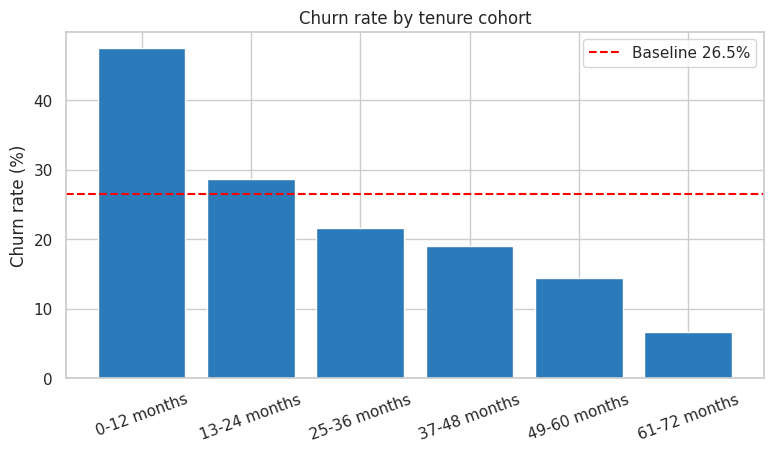

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(cohort.index.astype(str), cohort["Churn Rate %"], color="#2b7bba")
ax.axhline(baseline, color="red", ls="--", label=f"Baseline {baseline:.1f}%")
ax.set_title("Churn rate by tenure cohort")
ax.set_ylabel("Churn rate (%)")
ax.legend()
plt.xticks(rotation=20)
plt.show()

## 5. Contract type

The task asks for contract types (Month-to-Month vs 1-Year and 2-Year), so I looked at contract on its own first and then combined it with tenure.

In [8]:
contract = df.groupby("Contract").agg(
    Customers=("customerID", "count"),
    Churned=("ChurnFlag", "sum"),
    Avg_Monthly_Charge=("MonthlyCharges", "mean"),
)
contract["Churn Rate %"] = contract["Churned"] / contract["Customers"] * 100
contract.round(1)

,Customers,Churned,Avg_Monthly_Charge,Churn Rate %
Contract,,,,
Month-to-month,3875,1655,66.4,42.7
One year,1473,166,65.0,11.3
Two year,1695,48,60.8,2.8


Number of customers in each cell:


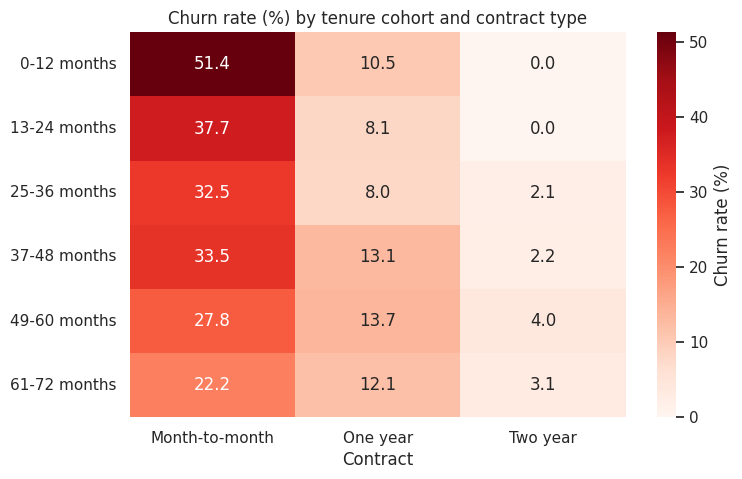

Contract,Month-to-month,One year,Two year
Tenure Cohort,,,
0-12 months,1994,124,68
13-24 months,737,197,90
25-36 months,486,250,96
37-48 months,316,268,178
49-60 months,234,321,277
61-72 months,108,313,986


In [9]:
# Cohort matrix: churn rate for every tenure cohort and contract type
matrix = df.pivot_table(index="Tenure Cohort", columns="Contract", values="ChurnFlag", aggfunc="mean", observed=True) * 100
counts = df.pivot_table(index="Tenure Cohort", columns="Contract", values="ChurnFlag", aggfunc="count", observed=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(matrix, annot=True, fmt=".1f", cmap="Reds", ax=ax, cbar_kws={"label": "Churn rate (%)"})
ax.set_title("Churn rate (%) by tenure cohort and contract type")
ax.set_ylabel("")
plt.show()

print("Number of customers in each cell:")
counts

## 6. Retention curves

A retention curve shows what share of customers are still subscribed after a given number of months. Because many customers are still active (we do not see when they will leave), I used the Kaplan-Meier method. At each month it takes the customers who were still active and removes the ones who churned in that month.

Month-to-month: 70% still subscribed after 12 months, 49% after 36 months, 13% after 72 months
One year: 99% still subscribed after 12 months, 96% after 36 months, 57% after 72 months
Two year: 100% still subscribed after 12 months, 100% after 36 months, 94% after 72 months


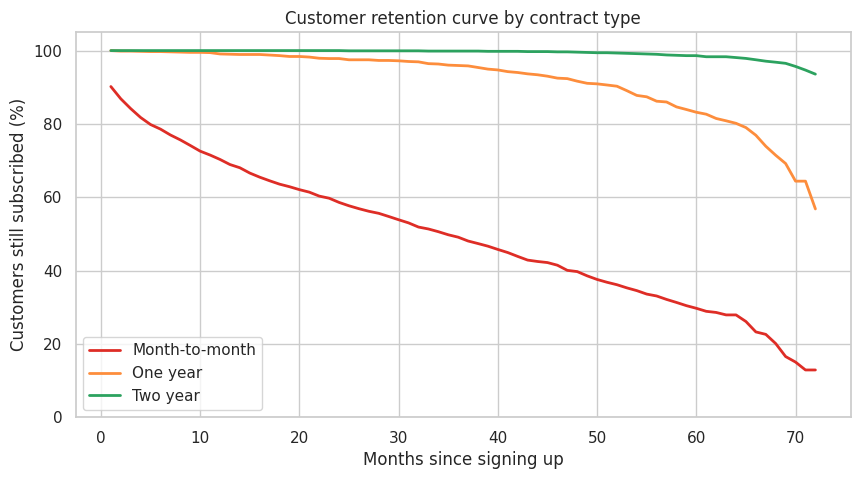

In [10]:
def retention_curve(data):
    survival = []
    s = 1.0
    for t in range(1, 73):
        at_risk = (data["tenure"] >= t).sum()
        left = ((data["tenure"] == t) & (data["ChurnFlag"] == 1)).sum()
        if at_risk > 0:
            s *= 1 - left / at_risk
        survival.append(s)
    return pd.Series(survival, index=range(1, 73))

fig, ax = plt.subplots(figsize=(10, 5))
colors = {"Month-to-month": "#de2d26", "One year": "#fd8d3c", "Two year": "#2ca25f"}
for name, g in df.groupby("Contract"):
    ax.plot(retention_curve(g) * 100, label=name, color=colors[name], lw=2)
ax.set_title("Customer retention curve by contract type")
ax.set_xlabel("Months since signing up")
ax.set_ylabel("Customers still subscribed (%)")
ax.set_ylim(0, 105)
ax.legend()
plt.show()

for name, g in df.groupby("Contract"):
    r = retention_curve(g)
    print(f"{name}: {r[12] * 100:.0f}% still subscribed after 12 months, {r[36] * 100:.0f}% after 36 months, {r[72] * 100:.0f}% after 72 months")

## 7. Payment method and monthly charges

In [11]:
pay = df.groupby("PaymentMethod").agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"))
pay["Churn_Rate"] *= 100
pay.sort_values("Churn_Rate", ascending=False).round(1)

,Customers,Churn_Rate
PaymentMethod,,
Electronic check,2365,45.3
Mailed check,1612,19.1
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2


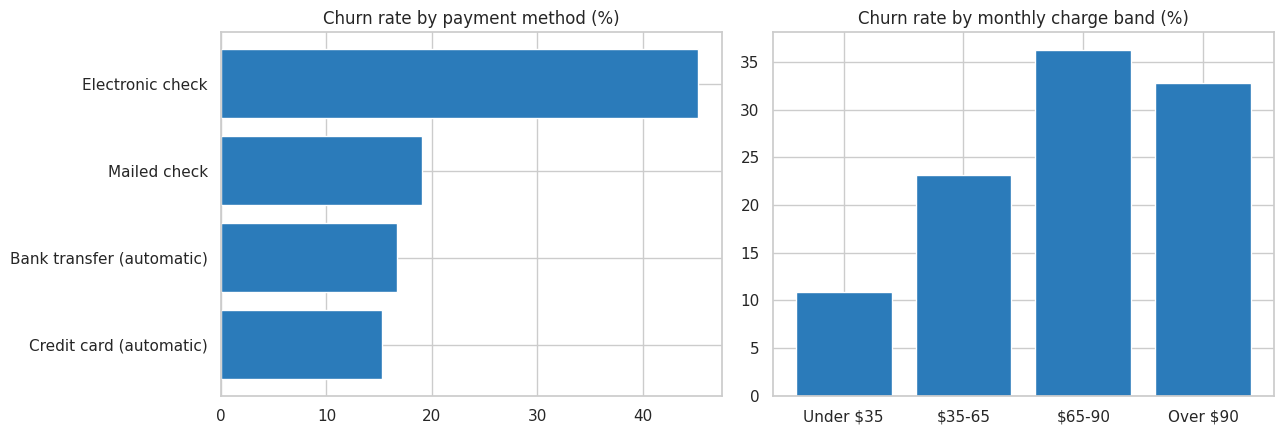

,Customers,Churn_Rate
Charge Band,,
Under $35,1735,10.9
$35-65,1409,23.1
$65-90,2160,36.3
Over $90,1739,32.8


In [12]:
df["Charge Band"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 65, 90, 125],
                           labels=["Under $35", "$35-65", "$65-90", "Over $90"])
charge = df.groupby("Charge Band", observed=True).agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"))
charge["Churn_Rate"] *= 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(pay.sort_values("Churn_Rate").index, pay.sort_values("Churn_Rate")["Churn_Rate"], color="#2b7bba")
ax[0].set_title("Churn rate by payment method (%)")
ax[1].bar(charge.index.astype(str), charge["Churn_Rate"], color="#2b7bba")
ax[1].set_title("Churn rate by monthly charge band (%)")
plt.tight_layout()
plt.show()
charge.round(1)

## 8. Service tier and high-risk segments

In [13]:
tier = df.groupby("InternetService").agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"), Avg_Monthly=("MonthlyCharges", "mean"))
tier["Churn_Rate"] *= 100
tier.round(1)

,Customers,Churn_Rate,Avg_Monthly
InternetService,,,
DSL,2421,19.0,58.1
Fiber optic,3096,41.9,91.5
No,1526,7.4,21.1


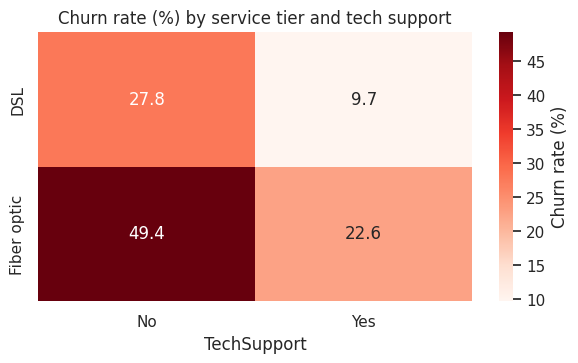

In [14]:
# Churn heatmap: internet service tier vs tech support
heat = df[df["InternetService"] != "No"].pivot_table(index="InternetService", columns="TechSupport", values="ChurnFlag", aggfunc="mean") * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", ax=ax, cbar_kws={"label": "Churn rate (%)"})
ax.set_title("Churn rate (%) by service tier and tech support")
ax.set_ylabel("")
plt.show()

In [15]:
# Look for high-risk segments by combining several features
df["Segment"] = np.where(
    (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No") & (df["Contract"] == "Month-to-month"),
    "Fiber + no tech support + month-to-month", "Everyone else")
seg = df.groupby("Segment").agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"))
seg["Churn_Rate"] *= 100
seg["Share of all churners %"] = df.groupby("Segment")["ChurnFlag"].sum() / df["ChurnFlag"].sum() * 100
seg.round(1)

,Customers,Churn_Rate,Share of all churners %
Segment,,,
Everyone else,5247,15.9,44.7
Fiber + no tech support + month-to-month,1796,57.5,55.3


In [16]:
# Other customer features
for col in ["SeniorCitizen", "Partner", "Dependents", "PaperlessBilling", "gender"]:
    r = df.groupby(col)["ChurnFlag"].mean() * 100
    print(col, {k: f"{v:.1f}%" for k, v in r.items()})

SeniorCitizen {'No': '23.6%', 'Yes': '41.7%'}
Partner {'No': '33.0%', 'Yes': '19.7%'}
Dependents {'No': '31.3%', 'Yes': '15.5%'}
PaperlessBilling {'No': '16.3%', 'Yes': '33.6%'}
gender {'Female': '26.9%', 'Male': '26.2%'}


## 9. Findings and recommendations


**Overall:** 1,869 of 7,043 customers churned, a baseline churn rate of 26.5%. Those customers were paying $139,131 a month, which is 30.5% of monthly revenue.

**1. Contract type is the biggest driver of churn.**
Month-to-month customers churn at 42.7%, compared with 11.3% for one-year and only 2.8% for two-year contracts. Month-to-month customers make up 88.6% of everyone who left. The retention curves show it clearly: after 12 months, 70% of month-to-month customers are still subscribed, against 99% for one-year and 100% for two-year contracts.

**2. The first year is the danger zone.**
Customers in their first 12 months churn at 47.4%, and this falls steadily with tenure, down to 6.6% for customers who have stayed 61 to 72 months. For month-to-month customers in their first year the churn rate is 51.4%. 1,994 customers sit in this group, so it is the best place to start.

**3. Fiber optic customers without tech support are the highest-risk group.**
Fiber optic churn is 41.9%, compared with 19.0% for DSL and 7.4% for customers with no internet. Having tech support cuts churn a lot in both tiers (fiber: 49.4% without it, 22.6% with it; DSL: 27.8% without, 9.7% with). The group of fiber customers with no tech support on a month-to-month contract has 1,796 customers (about 25% of the base), a 57.5% churn rate, and accounts for 55.3% of all churners.

**4. Payment method and price point also matter.**
Electronic check customers churn at 45.3%, while customers on automatic payments (bank transfer or credit card) churn at only 15 to 17%. Electronic check users make up 57% of all churners. Customers paying $65 to $90 a month churn the most (36.3%), while those paying under $35 churn at 10.9%.

**5. Other customer groups.**
Senior citizens churn at 41.7% (against 23.6%), customers without a partner or dependents churn much more, and paperless billing customers churn at 33.6% against 16.3%. Gender makes almost no difference (26.9% vs 26.2%). These variables overlap with contract type, so they should be read as supporting evidence rather than separate causes.

**Strategic retention recommendations**
1. **Move month-to-month customers onto longer contracts.** Offer a discount or a free service for switching to a one-year plan, especially around month 6 to 10.
2. **Build a first-year program.** Check in with new customers, give onboarding help and watch usage in the first 12 months.
3. **Bundle tech support with fiber plans.** It cuts churn by more than half and could be offered free for the first few months.
4. **Push automatic payments.** A small bill credit for moving from electronic check to automatic payment could reduce churn in the largest churn group.
5. **Review fiber pricing and quality.** Fiber customers are paying about $91 a month and leaving at almost 42%, so price versus service quality should be investigated.

**Limits of this analysis:** the data is a single snapshot with no dates, so cohorts are based on tenure rather than the actual sign-up month. Also, this shows what is linked to churn, but it does not prove that changing one factor will cause customers to stay.
